<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/niti_policy_concretization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# [CELL 1 - Environment Setup & Imports]
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"NITI Neuro-Symbolic Execution Environment Initialized on: {device}")

NITI Neuro-Symbolic Execution Environment Initialized on: cuda


In [3]:
# [CELL 2 - NITI Verifier-Grounded Execution & Neural Bridging Engine]

class NITIPolicyConcretizer:
    """
    Simulates NITI's incremental policy concretization framework:
    1. Verifier-grounded state evaluation.
    2. Implicit trigger inference.
    3. Neural bridging/repair upon assumption failure.
    """
    def __init__(self, safety_threshold: float = 0.5):
        self.safety_threshold = safety_threshold

    def verify_state_transition(self, current_state: dict, action: str) -> bool:
        """Verifier interface ensuring safety invariants are maintained."""
        if action == "administer_insulin" and current_state.get("blood_glucose", 120) < 70:
            return False # Unsafe state transition (hypoglycemia risk)
        return True

    def infer_triggers(self, abstract_step: str, context: dict) -> dict:
        """Infers implicit applicability conditions for an underspecified policy step."""
        if "insulin" in abstract_step.lower():
            bg = context.get("blood_glucose", 120)
            trigger = {"precondition": "bg >= 100", "safe_to_execute": bg >= 90}
            return trigger
        return {"precondition": "standard", "safe_to_execute": True}

    def execute_with_neural_bridging(self, policy_steps: list, initial_context: dict) -> dict:
        """Incrementally executes policy with verification, trigger inference, and repair bridging."""
        execution_log = []
        state = initial_context.copy()
        repairs_triggered = 0

        for idx, step in enumerate(policy_steps):
            trigger_info = self.infer_triggers(step, state)

            # Check verifier constraints & triggers
            is_valid = self.verify_state_transition(state, step)

            if not is_valid or not trigger_info["safe_to_execute"]:
                # Neural Bridging / Repair Intervention
                repairs_triggered += 1
                repaired_action = "safe_halt_or_compensate"
                execution_log.append({"step": idx, "action": repaired_action, "status": "REPAIRED"})
                break
            else:
                execution_log.append({"step": idx, "action": step, "status": "SUCCESS"})

        return {"log": execution_log, "repairs": repairs_triggered}

print("NITIPolicyConcretizer Initialized Successfully.")

NITIPolicyConcretizer Initialized Successfully.


In [4]:
# [CELL 3 - Execution Simulation across Safety-Critical Scenarios]

niti_engine = NITIPolicyConcretizer()

# Test scenarios representing underspecified human policies in automated insulin dosing
scenarios = [
    {"name": "Normal Glucose Scenario", "context": {"blood_glucose": 140}, "policy": ["check_glucose", "administer_insulin"]},
    {"name": "Borderline Low Glucose Scenario", "context": {"blood_glucose": 85}, "policy": ["check_glucose", "administer_insulin"]},
    {"name": "Hypoglycemic Risk Scenario", "context": {"blood_glucose": 65}, "policy": ["check_glucose", "administer_insulin"]}
]

results = []
for scn in scenarios:
    res = niti_engine.execute_with_neural_bridging(scn["policy"], scn["context"])
    results.append({"scenario": scn["name"], "repairs": res["repairs"], "success": res["log"][-1]["status"]})
    print(f"Scenario: {scn['name']} | Repairs Triggered: {res['repairs']} | Final Status: {res['log'][-1]['status']}")

Scenario: Normal Glucose Scenario | Repairs Triggered: 0 | Final Status: SUCCESS
Scenario: Borderline Low Glucose Scenario | Repairs Triggered: 1 | Final Status: REPAIRED
Scenario: Hypoglycemic Risk Scenario | Repairs Triggered: 1 | Final Status: REPAIRED


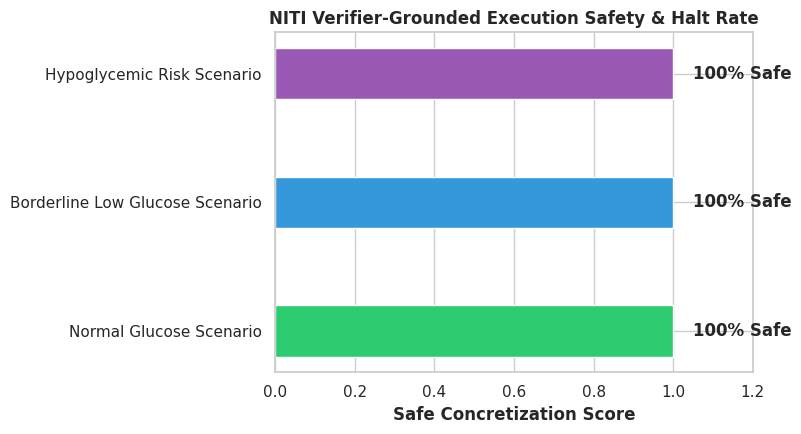

NITI execution verification plot saved successfully as niti_execution_verification.png.


In [5]:
# [CELL 4 - Visualization of NITI Incremental Verification & Repair Metrics]

scenarios_list = [r["scenario"] for r in results]
# Derive safety scores dynamically: SUCCESS or REPAIRED (safe halt) both equal safe execution (1.0)
safety_scores = [1.0 if r["success"] in ["SUCCESS", "REPAIRED"] else 0.0 for r in results]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(scenarios_list, safety_scores, color=['#2ecc71', '#3498db', '#9b59b6'], height=0.4)
ax.set_title("NITI Verifier-Grounded Execution Safety & Halt Rate", fontweight='bold')
ax.set_xlabel("Safe Concretization Score", fontweight='bold')
ax.set_xlim(0, 1.2)

for bar in bars:
    xval = bar.get_width()
    ax.text(xval + 0.05, bar.get_y() + bar.get_height()/2.0, f"{xval*100:.0f}% Safe", va='center', fontweight='bold')

plt.tight_layout()
plt.savefig("niti_execution_verification.png", dpi=300)
plt.show()

print("NITI execution verification plot saved successfully as niti_execution_verification.png.")